# Tree-Based Insurance Claim Fraud Detection

**Day 31 — Week 6 Project 

Objective: identify potentially fraudulent insurance claims for human investigation while considering class imbalance, investigation costs, limited review capacity, and explainability.

The notebook follows the eight steps in the project brief. Run it from top to bottom with `insurance_claims.csv` in the same folder. The test set is reserved for the final evaluation and is not used for model selection or threshold tuning.

## Step 1 — Understand the problem before modelling

Fraud is the minority class. Accuracy alone can be misleading, so this notebook reports Average Precision (PR-focused ranking), precision, recall, ROC-AUC, and Brier score. Average Precision is compared with the random-ranking baseline, which equals the positive-class prevalence.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score,
    roc_auc_score, brier_score_loss, log_loss, confusion_matrix
)
from sklearn.base import clone
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
TARGET = "is_fraud"

d:\AI ML Internship\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("insurance_claims.csv")

required_columns = {
    "claim_id", "claim_amount", "customer_tenure_months", "age",
    "prior_claims", "days_to_report", "policy_type", "region",
    "channel", TARGET
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

if df[TARGET].isna().any():
    raise ValueError("Target column contains missing values.")
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("Target is expected to contain binary labels 0 and 1.")

print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("Data type"))

Dataset shape: (8000, 10)


,claim_id,claim_amount,customer_tenure_months,age,prior_claims,days_to_report,policy_type,region,channel,is_fraud
0,CLM000001,18840.68,31,30.0,0,0.0,Premium,South,Online,0
1,CLM000002,6425.39,19,42.0,0,NaN,Basic,East,Broker,0
2,CLM000003,26912.90,8,55.0,1,11.0,Basic,North,Broker,1
3,CLM000004,31333.77,26,57.0,0,7.0,Standard,East,Broker,0
4,CLM000005,3100.04,3,58.0,1,18.0,Standard,South,Agent,0


,Data type
claim_id,str
claim_amount,float64
customer_tenure_months,int64
age,float64
prior_claims,int64
days_to_report,float64
policy_type,str
region,str
channel,str
is_fraud,int64


In [3]:
target_counts = df[TARGET].value_counts()
fraud_count = int(target_counts.get(1, 0))
legitimate_count = int(target_counts.get(0, 0))
fraud_rate = fraud_count / len(df)
imbalance_ratio = legitimate_count / fraud_count
baseline_accuracy = legitimate_count / len(df)
random_baseline_ap = fraud_rate

print(f"Total claims: {len(df):,}")
print(f"Fraudulent claims: {fraud_count:,}")
print(f"Legitimate claims: {legitimate_count:,}")
print(f"Fraud rate: {fraud_rate:.4%}")
print(f"Imbalance ratio (legitimate:fraud): {imbalance_ratio:.2f}:1")
print(f"Accuracy if every claim is predicted legitimate: {baseline_accuracy:.2%}")
print(f"Random-ranking Average Precision baseline: {random_baseline_ap:.4f}")

Total claims: 8,000
Fraudulent claims: 295
Legitimate claims: 7,705
Fraud rate: 3.6875%
Imbalance ratio (legitimate:fraud): 26.12:1
Accuracy if every claim is predicted legitimate: 96.31%
Random-ranking Average Precision baseline: 0.0369


**Interpretation:** a model that predicts every claim as legitimate can have high accuracy while detecting no fraud. ROC-AUC measures ranking across thresholds but can look reassuring when negatives greatly outnumber positives. Average Precision is more informative for the rare positive class; a score must be compared with the random baseline and with alternative models on the same split.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
display(missing_summary[missing_summary["Missing Count"] > 0])

,Missing Count,Missing Percentage
age,120,1.50
days_to_report,90,1.12


## Step 2 — Explore with a purpose

The plots below use the training portion only. Each plot investigates whether observed fraud rates vary across a feature; observed association is not proof of causation. Group counts are displayed to help identify unstable rates from small groups.

In [5]:
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE, stratify=df[TARGET]
)
dev_df, val_df = train_test_split(
    train_df, test_size=0.20, random_state=RANDOM_STATE, stratify=train_df[TARGET]
)

print(f"Development training rows: {len(dev_df):,}")
print(f"Validation rows: {len(val_df):,}")
print(f"Untouched final test rows: {len(test_df):,}")
print(f"Training fraud rate: {dev_df[TARGET].mean():.2%}")
print(f"Validation fraud rate: {val_df[TARGET].mean():.2%}")

Development training rows: 5,120
Validation rows: 1,280
Untouched final test rows: 1,600
Training fraud rate: 3.69%
Validation fraud rate: 3.67%


Fraud rate by channel:


,Fraud_Rate,Claims
channel,,
Broker,0.068931,1001
Agent,0.029247,2496
Online,0.028959,1623


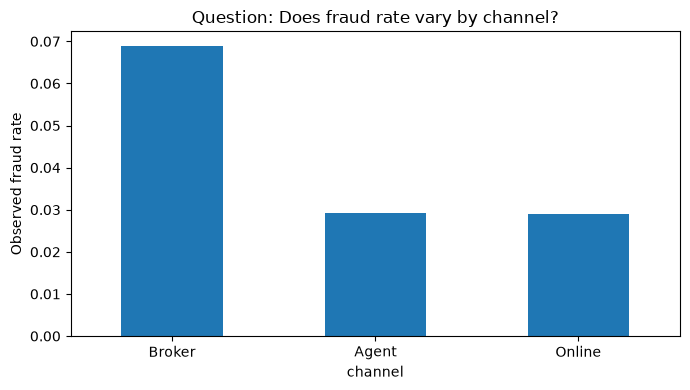

Conclusion: compare both fraud rates and group counts; differences are exploratory, not causal.
Fraud rate by policy_type:


,Fraud_Rate,Claims
policy_type,,
Basic,0.040482,2322
Standard,0.039306,1959
Premium,0.021454,839


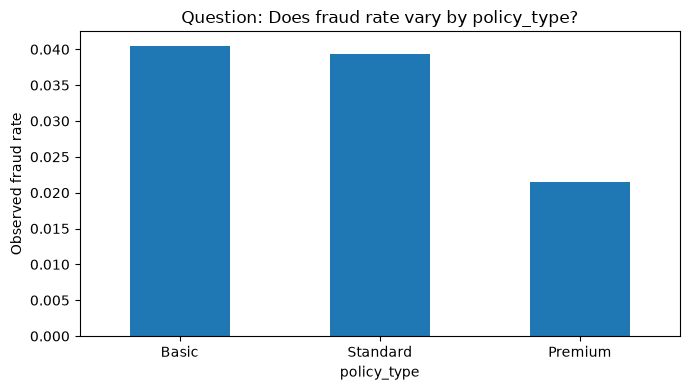

Conclusion: compare both fraud rates and group counts; differences are exploratory, not causal.
Fraud rate by region:


,Fraud_Rate,Claims
region,,
South,0.044961,1290
West,0.036462,1289
East,0.033439,1256
North,0.032685,1285


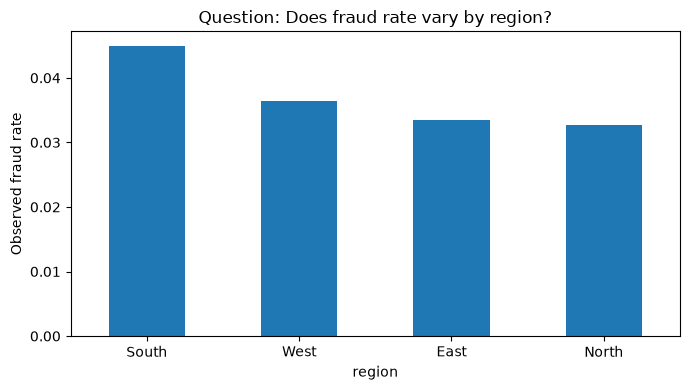

Conclusion: compare both fraud rates and group counts; differences are exploratory, not causal.


In [6]:
categorical_features = ["channel", "policy_type", "region"]
for feature in categorical_features:
    summary = dev_df.groupby(feature, dropna=False)[TARGET].agg(
        Fraud_Rate="mean", Claims="count"
    ).sort_values("Fraud_Rate", ascending=False)
    print(f"Fraud rate by {feature}:")
    display(summary)
    ax = summary["Fraud_Rate"].plot(kind="bar", figsize=(7, 4))
    ax.set(title=f"Question: Does fraud rate vary by {feature}?",
           xlabel=feature, ylabel="Observed fraud rate")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print("Conclusion: compare both fraud rates and group counts; differences are exploratory, not causal.")

,Fraud_Rate,Claims
prior_claims,,
0,0.020008,2499
1,0.038440,1795
2,0.065625,640
3,0.133333,150
4,0.206897,29
5,0.285714,7


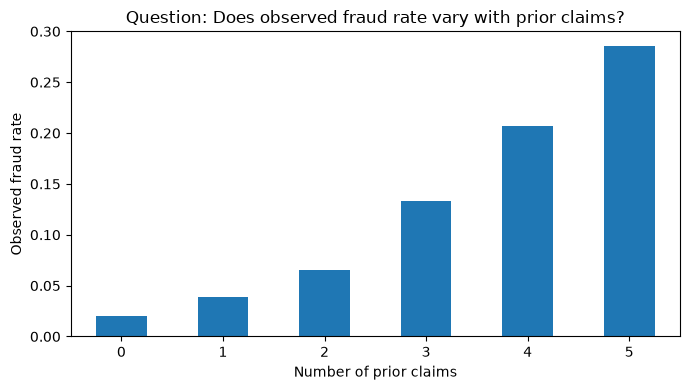

Conclusion: use the displayed rates and counts to judge whether prior-claim history may be informative.


In [7]:
prior_summary = dev_df.groupby("prior_claims")[TARGET].agg(
    Fraud_Rate="mean", Claims="count"
).sort_index()
display(prior_summary)
ax = prior_summary["Fraud_Rate"].plot(kind="bar", figsize=(7, 4))
ax.set(title="Question: Does observed fraud rate vary with prior claims?",
       xlabel="Number of prior claims", ylabel="Observed fraud rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Conclusion: use the displayed rates and counts to judge whether prior-claim history may be informative.")

,Fraud_Rate,Claims
claim_amount_group,,
"(1999.999, 7431.882]",0.021484,1024
"(7431.882, 12061.264]",0.017578,1024
"(12061.264, 17877.932]",0.030273,1024
"(17877.932, 28589.778]",0.041992,1024
"(28589.778, 234037.61]",0.073242,1024


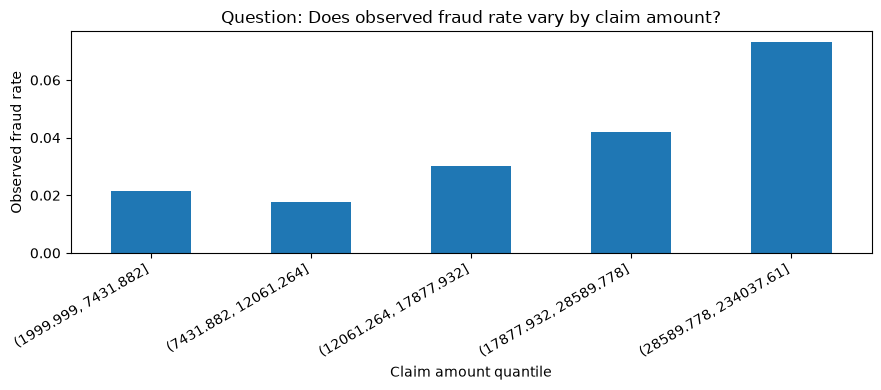

Conclusion: differences suggest a possible association; confirm usefulness through validation.


In [8]:
dev_df = dev_df.copy()
dev_df["claim_amount_group"] = pd.qcut(
    dev_df["claim_amount"], q=5, duplicates="drop"
)
amount_summary = dev_df.groupby("claim_amount_group", observed=True)[TARGET].agg(
    Fraud_Rate="mean", Claims="count"
)
display(amount_summary)
ax = amount_summary["Fraud_Rate"].plot(kind="bar", figsize=(9, 4))
ax.set(title="Question: Does observed fraud rate vary by claim amount?",
       xlabel="Claim amount quantile", ylabel="Observed fraud rate")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
print("Conclusion: differences suggest a possible association; confirm usefulness through validation.")
dev_df = dev_df.drop(columns=["claim_amount_group"])

Fraud rate by age availability:


,Fraud_Rate,Claims
Missing_Status,,
Missing,0.025974,77
Recorded,0.037081,5043


age: median=41.000, mean=41.002, skewness=0.157


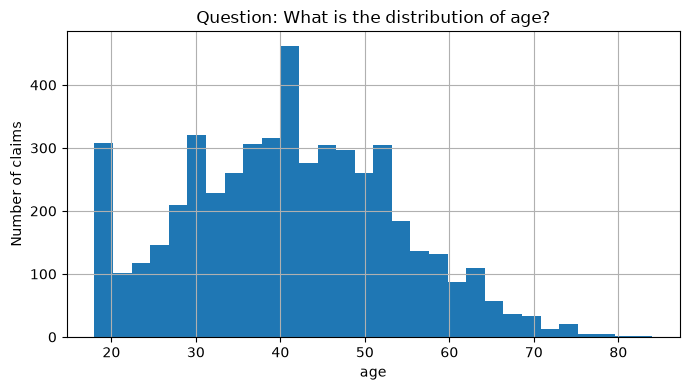

Fraud rate by days_to_report availability:


,Fraud_Rate,Claims
Missing_Status,,
Missing,0.000000,58
Recorded,0.037337,5062


days_to_report: median=4.000, mean=5.536, skewness=2.013


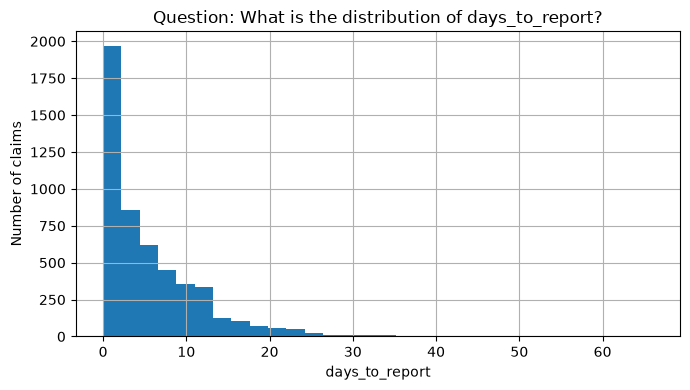

In [9]:
for feature in ["age", "days_to_report"]:
    availability = dev_df.assign(
        Missing_Status=np.where(dev_df[feature].isna(), "Missing", "Recorded")
    ).groupby("Missing_Status")[TARGET].agg(Fraud_Rate="mean", Claims="count")
    print(f"Fraud rate by {feature} availability:")
    display(availability)

    print(f"{feature}: median={dev_df[feature].median():.3f}, "
          f"mean={dev_df[feature].mean():.3f}, "
          f"skewness={dev_df[feature].skew():.3f}")
    dev_df[feature].dropna().hist(bins=30, figsize=(7, 4))
    plt.title(f"Question: What is the distribution of {feature}?")
    plt.xlabel(feature)
    plt.ylabel("Number of claims")
    plt.tight_layout()
    plt.show()

### Missing-value decision

Use median imputation for numeric variables and add missingness indicators for numeric columns with missing values. Median imputation is less sensitive to extreme values than mean imputation, which is useful to consider for a skewed variable such as `days_to_report`. Use most-frequent imputation for categorical variables. Fit all imputers on training data only, inside the preprocessing pipeline, to avoid leakage. The missingness analysis is descriptive and does not prove that missingness predicts fraud.

## Step 3 — Compare three model families

Decision Tree, Random Forest, and XGBoost use the same development/validation split, features, and preprocessing. Average Precision is the primary ranking metric because fraud is rare. The train–validation gap is a diagnostic for possible overfitting, not a metric to optimize in isolation.

In [10]:
numeric_features = [
    "claim_amount", "customer_tenure_months", "age",
    "prior_claims", "days_to_report"
]
categorical_features = ["policy_type", "region", "channel"]
feature_columns = numeric_features + categorical_features

X_train = dev_df[feature_columns].copy()
y_train = dev_df[TARGET].copy()
X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].copy()

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

trained_models = {}
model_rows = []
for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])
    pipeline.fit(X_train, y_train)
    train_prob = pipeline.predict_proba(X_train)[:, 1]
    val_prob = pipeline.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    model_rows.append({
        "Model": name,
        "Train Average Precision": average_precision_score(y_train, train_prob),
        "Validation Average Precision": average_precision_score(y_val, val_prob),
        "Train-Validation Gap": (
            average_precision_score(y_train, train_prob)
            - average_precision_score(y_val, val_prob)
        ),
        "Validation Recall at 0.5": recall_score(y_val, val_pred, zero_division=0),
        "Validation Precision at 0.5": precision_score(y_val, val_pred, zero_division=0),
        "Validation ROC-AUC": roc_auc_score(y_val, val_prob),
        "Validation Brier Score": brier_score_loss(y_val, val_prob)
    })
    trained_models[name] = pipeline

model_results = pd.DataFrame(model_rows).sort_values(
    "Validation Average Precision", ascending=False
).reset_index(drop=True)
display(model_results.round(4))
best_model_name = model_results.loc[0, "Model"]
print("Selected model family for the imbalance experiment:", best_model_name)
print("Selection basis: highest validation Average Precision; the gap and other metrics remain trade-offs.")

,Model,Train Average Precision,Validation Average Precision,Train-Validation Gap,Validation Recall at 0.5,Validation Precision at 0.5,Validation ROC-AUC,Validation Brier Score
0,XGBoost,0.6485,0.1936,0.4549,0.0426,0.5,0.8360,0.0327
1,Random Forest,0.8490,0.1722,0.6768,0.0000,0.0,0.8163,0.0330
2,Decision Tree,0.1842,0.0800,0.1042,0.0000,0.0,0.7214,0.0357


Selected model family for the imbalance experiment: XGBoost
Selection basis: highest validation Average Precision; the gap and other metrics remain trade-offs.


**Model comparison conclusion:** carry forward the model with the highest validation Average Precision, while considering its train–validation gap and precision/recall trade-off. A Decision Tree would be preferable if its performance were sufficiently close and interpretability were the priority; Random Forest and XGBoost may improve ranking but are more complex to explain. The next step tests whether imbalance handling changes the choice.

## Step 4 — Handle class imbalance deliberately

Compare no handling, class weighting, and random oversampling. Oversampling is inside an imbalanced-learn pipeline, so it is applied only to training data. Validation data retains the real class balance. Precision, recall, Average Precision, and Brier score are reported at threshold 0.5 for a consistent comparison.

In [11]:
weighted_classifier = clone(models[best_model_name])
if best_model_name in ["Decision Tree", "Random Forest"]:
    weighted_classifier.set_params(class_weight="balanced")
else:
    negative_count = int((y_train == 0).sum())
    positive_count = int((y_train == 1).sum())
    weighted_classifier.set_params(scale_pos_weight=negative_count / positive_count)

weighted_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", weighted_classifier)
])
weighted_model.fit(X_train, y_train)

oversampled_model = ImbPipeline([
    ("preprocessor", clone(preprocessor)),
    ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
    ("classifier", clone(models[best_model_name]))
])
oversampled_model.fit(X_train, y_train)

comparison_models = {
    "No Handling": trained_models[best_model_name],
    "Class Weights": weighted_model,
    "Random Oversampling": oversampled_model
}
imbalance_rows = []
for name, model in comparison_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.5).astype(int)
    imbalance_rows.append({
        "Method": name,
        "Average Precision": average_precision_score(y_val, prob),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Brier Score": brier_score_loss(y_val, prob)
    })
imbalance_results = pd.DataFrame(imbalance_rows).sort_values(
    "Average Precision", ascending=False
).reset_index(drop=True)
display(imbalance_results.round(4))

,Method,Average Precision,Recall,Precision,Brier Score
0,Class Weights,0.2230,0.5745,0.1607,0.0986
1,No Handling,0.1936,0.0426,0.5000,0.0327
2,Random Oversampling,0.1590,0.5319,0.1323,0.1082


**Decision rule:** choose the imbalance strategy using the business objective, not one metric alone. Higher recall can surface more fraud but often increases false positives; a worse Brier score indicates less reliable probabilities. The class-weighted model is carried into threshold analysis because it explicitly increases the importance of the minority class. Its probabilities are calibrated in Step 6 before probability-based operational use.

## Step 5 — Choose a threshold from costs, not habit

Cost assumptions from the brief are expressed in relative units: investigating a legitimate claim costs 1 unit; missing a fraudulent claim costs 20 units. The alternative scenario uses a 5:1 ratio. These are simplified assumptions for the required analysis, not a complete accounting of claim payouts or operational costs.

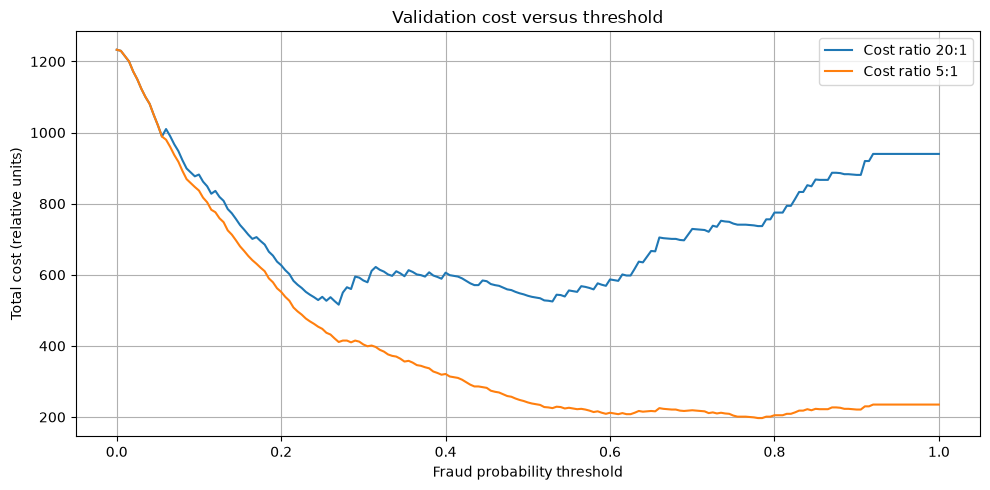

Cost-optimal threshold (20:1): 0.270
Minimum validation cost (20:1): 516
Cost at threshold 0.50 (20:1): 541
Cost reduction versus 0.50: 4.62%
Cost-optimal threshold (5:1): 0.780
Minimum validation cost (5:1): 197
Flagged validation claims at 20:1 threshold: 416 / 1280 (32.50%)


In [12]:
selected_model = weighted_model
val_probabilities = selected_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0, 1, 201)
investigation_cost = 1

cost_rows = []
for threshold in thresholds:
    pred = (val_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    cost_rows.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Flagged Claims": int(pred.sum()),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Cost 20:1": fp * investigation_cost + fn * 20 * investigation_cost,
        "Cost 5:1": fp * investigation_cost + fn * 5 * investigation_cost
    })
threshold_results = pd.DataFrame(cost_rows)

plt.figure(figsize=(10, 5))
plt.plot(threshold_results["Threshold"], threshold_results["Cost 20:1"], label="Cost ratio 20:1")
plt.plot(threshold_results["Threshold"], threshold_results["Cost 5:1"], label="Cost ratio 5:1")
plt.xlabel("Fraud probability threshold")
plt.ylabel("Total cost (relative units)")
plt.title("Validation cost versus threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_20 = threshold_results.loc[threshold_results["Cost 20:1"].idxmin()]
best_5 = threshold_results.loc[threshold_results["Cost 5:1"].idxmin()]
baseline_05 = threshold_results.iloc[(threshold_results["Threshold"] - 0.5).abs().argmin()]

print(f"Cost-optimal threshold (20:1): {best_20['Threshold']:.3f}")
print(f"Minimum validation cost (20:1): {best_20['Cost 20:1']:.0f}")
print(f"Cost at threshold 0.50 (20:1): {baseline_05['Cost 20:1']:.0f}")
improvement = 100 * (baseline_05["Cost 20:1"] - best_20["Cost 20:1"]) / baseline_05["Cost 20:1"] if baseline_05["Cost 20:1"] else 0
print(f"Cost reduction versus 0.50: {improvement:.2f}%")
print(f"Cost-optimal threshold (5:1): {best_5['Threshold']:.3f}")
print(f"Minimum validation cost (5:1): {best_5['Cost 5:1']:.0f}")
print(f"Flagged validation claims at 20:1 threshold: {int(best_20['Flagged Claims'])} / {len(y_val)} "
      f"({best_20['Flagged Claims'] / len(y_val):.2%})")

### Investigation-capacity check

The brief states that the team can investigate approximately 200 claims per month, but the dataset does not specify the actual monthly incoming claim volume. Therefore, an exact monthly workload cannot be inferred from this dataset alone. The code below reports the maximum flagging rate that would fit capacity for a chosen monthly volume and gives an illustrative calculation for 1,000 monthly claims; replace that illustrative volume with the real business figure before deployment.

In [13]:
monthly_claim_volume = 1000  # Illustrative scenario only; replace with confirmed business volume.
capacity = 200
flagged_rate = best_20["Flagged Claims"] / len(y_val)
estimated_monthly_investigations = flagged_rate * monthly_claim_volume
maximum_capacity_rate = capacity / monthly_claim_volume

print(f"Flagging rate at cost-optimal threshold: {flagged_rate:.2%}")
print(f"Illustrative monthly volume: {monthly_claim_volume:,}")
print(f"Estimated investigations per month: {estimated_monthly_investigations:.1f}")
print(f"Investigation capacity: {capacity}")
print(f"Maximum flagging rate at this volume: {maximum_capacity_rate:.2%}")
print("Capacity check:", "within capacity" if estimated_monthly_investigations <= capacity else "exceeds capacity")
print("Operational decision: compare the cost-optimal threshold with capacity-feasible thresholds using confirmed monthly volume.")

Flagging rate at cost-optimal threshold: 32.50%
Illustrative monthly volume: 1,000
Estimated investigations per month: 325.0
Investigation capacity: 200
Maximum flagging rate at this volume: 20.00%
Capacity check: exceeds capacity
Operational decision: compare the cost-optimal threshold with capacity-feasible thresholds using confirmed monthly volume.


A lower fraud-miss cost (5:1 rather than 20:1) generally makes the model less willing to flag uncertain claims, but the direction and size of the threshold change must be verified from the calculated results. If the cost-optimal threshold exceeds capacity, capacity is an additional constraint: the business must decide whether to accept higher expected cost, increase review capacity, or prioritize the highest-risk claims.

## Step 6 — Decide about calibration

Class weighting changes the training objective and can distort probability estimates. Calibrate using cross-validation on the original, non-resampled training data so the calibration procedure sees the real class balance. Compare Brier score, log loss, and calibration curves on validation data.

,Model,Brier Score,Log Loss
0,Before calibration,0.0986,0.3269
1,After calibration,0.0332,0.1367


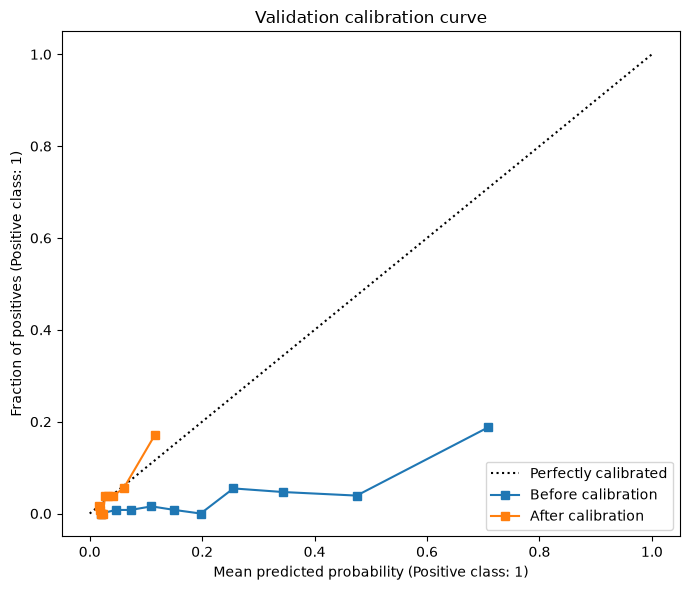

In [14]:
calibrated_model = CalibratedClassifierCV(
    estimator=clone(weighted_model),
    method="sigmoid",
    cv=3
)
calibrated_model.fit(X_train, y_train)

before_probabilities = weighted_model.predict_proba(X_val)[:, 1]
after_probabilities = calibrated_model.predict_proba(X_val)[:, 1]

calibration_results = pd.DataFrame({
    "Model": ["Before calibration", "After calibration"],
    "Brier Score": [
        brier_score_loss(y_val, before_probabilities),
        brier_score_loss(y_val, after_probabilities)
    ],
    "Log Loss": [
        log_loss(y_val, before_probabilities),
        log_loss(y_val, after_probabilities)
    ]
})
display(calibration_results.round(4))

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(
    y_val, before_probabilities, n_bins=10, strategy="quantile",
    name="Before calibration", ax=ax
)
CalibrationDisplay.from_predictions(
    y_val, after_probabilities, n_bins=10, strategy="quantile",
    name="After calibration", ax=ax
)
ax.set_title("Validation calibration curve")
plt.tight_layout()
plt.show()

**Calibration decision:** calibrated probabilities are important if a risk score will be multiplied by claim amount or interpreted as an estimated fraud probability. Ranking and calibration are different: a model can order claims correctly but systematically overstate or understate their probabilities. Calibration quality should be checked on data with the real fraud prevalence.

## Step 7 — Interpret the model

Use SHAP to explain the class-weighted tree model. SHAP values explain the underlying classifier's output; because calibration is a separate probability-mapping step, these plots explain the classifier rather than the calibrated probability mapping. Inspect feature correlations before interpreting feature importance.

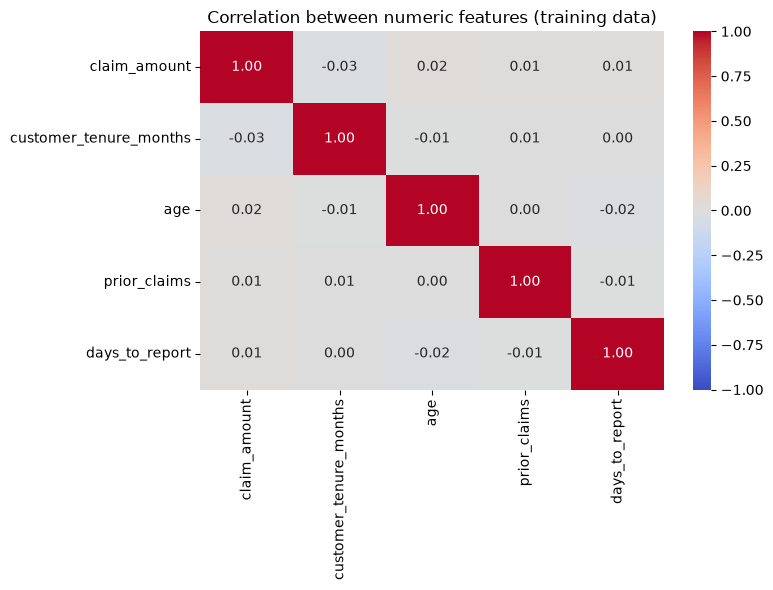

Interpretation: pairwise correlations show linear association only; weak correlation does not rule out nonlinear relationships.


In [15]:
correlation_data = X_train[numeric_features].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_data, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric features (training data)")
plt.tight_layout()
plt.show()
print("Interpretation: pairwise correlations show linear association only; weak correlation does not rule out nonlinear relationships.")

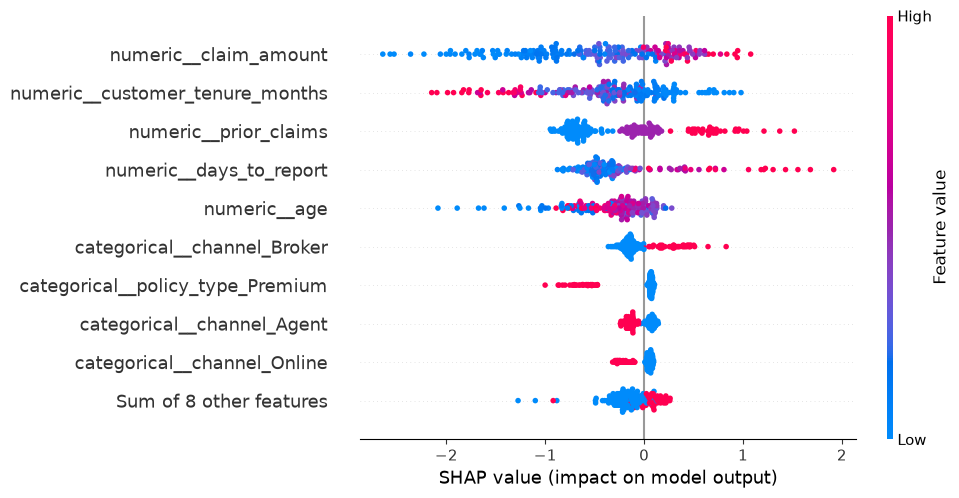

In [16]:
X_explain = X_val.sample(n=min(200, len(X_val)), random_state=RANDOM_STATE)
fitted_preprocessor = weighted_model.named_steps["preprocessor"]
fitted_classifier = weighted_model.named_steps["classifier"]

X_transformed = fitted_preprocessor.transform(X_explain)
if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()
feature_names = fitted_preprocessor.get_feature_names_out()
X_explain_transformed = pd.DataFrame(
    X_transformed, columns=feature_names, index=X_explain.index
)

explainer = shap.TreeExplainer(fitted_classifier)
shap_values = explainer(X_explain_transformed)

if len(shap_values.values.shape) == 3:
    fraud_shap_values = shap.Explanation(
        values=shap_values.values[:, :, 1],
        base_values=(
            shap_values.base_values[:, 1]
            if len(shap_values.base_values.shape) == 2
            else shap_values.base_values
        ),
        data=shap_values.data,
        feature_names=shap_values.feature_names
    )
else:
    fraud_shap_values = shap_values

shap.plots.beeswarm(fraud_shap_values)


Highest fraud score in sample
Underlying classifier score: 0.9188


,claim_amount,customer_tenure_months,age,prior_claims,days_to_report,policy_type,region,channel
7031,56627.25,2,48.0,1,2.0,Basic,North,Broker


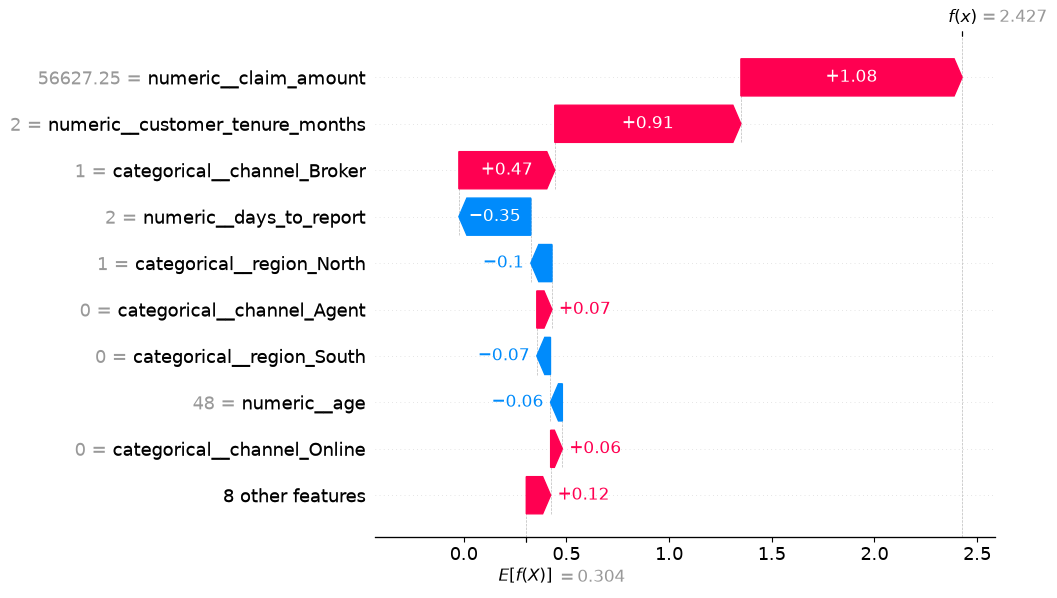


Lowest fraud score in sample
Underlying classifier score: 0.0058


,claim_amount,customer_tenure_months,age,prior_claims,days_to_report,policy_type,region,channel
4066,7636.65,61,19.0,0,5.0,Premium,South,Agent


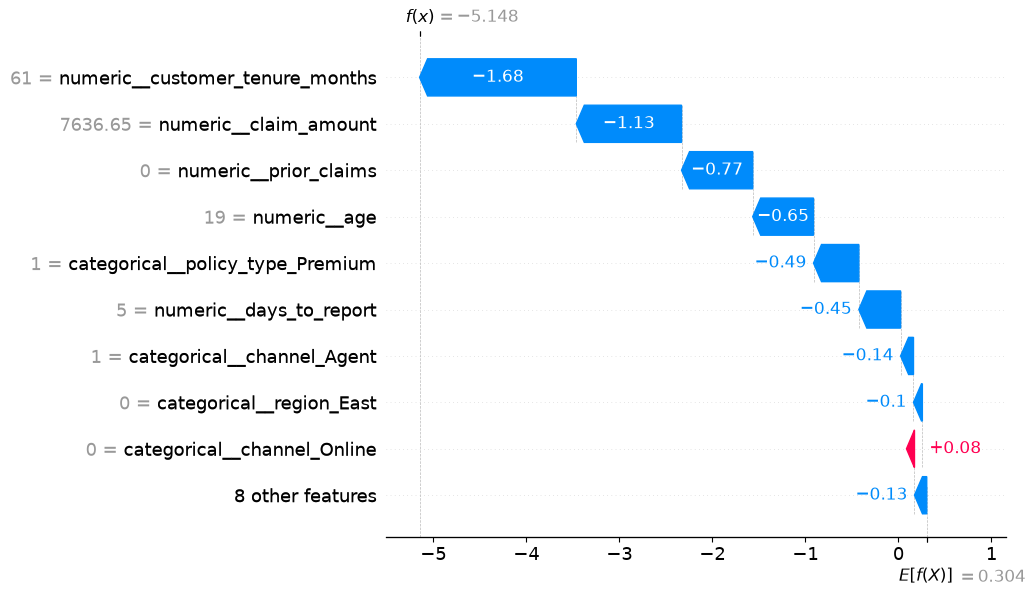


Score closest to 0.5 in sample
Underlying classifier score: 0.5077


,claim_amount,customer_tenure_months,age,prior_claims,days_to_report,policy_type,region,channel
2414,35881.45,29,57.0,1,1.0,Basic,West,Broker


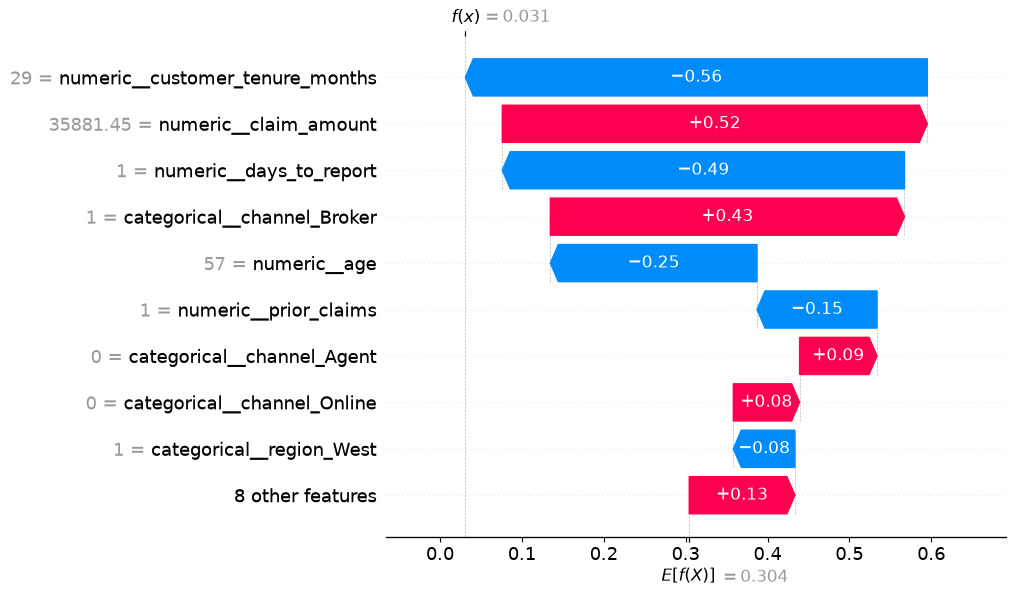

In [17]:
explanation_probabilities = weighted_model.predict_proba(X_explain)[:, 1]
selected_positions = {
    "Highest fraud score in sample": int(np.argmax(explanation_probabilities)),
    "Lowest fraud score in sample": int(np.argmin(explanation_probabilities)),
    "Score closest to 0.5 in sample": int(np.argmin(np.abs(explanation_probabilities - 0.5)))
}

for label, position in selected_positions.items():
    print(f"\n{label}")
    print(f"Underlying classifier score: {explanation_probabilities[position]:.4f}")
    display(X_explain.iloc[[position]])
    shap.plots.waterfall(fraud_shap_values[position])

**Interpretation checklist:** identify the highest-impact features and whether high or low feature values push predictions toward or away from fraud. Investigate suspicious drivers, proxies, or features that may not be available when a real claim is scored. SHAP describes model behavior; it does not prove fraud or causation. Individual cases should be reviewed by investigators.

## Final evaluation — untouched test set

All model and threshold choices above were made using training and validation data. The final test set is now used once to estimate performance on unseen claims. Do not use these test results to tune the model or threshold.

In [18]:
# Use the calibrated model for probability-based evaluation.
test_X = test_df[feature_columns].copy()
test_y = test_df[TARGET].copy()
test_probabilities = calibrated_model.predict_proba(test_X)[:, 1]

# Apply the validation-derived 20:1 cost threshold to calibrated probabilities.
# This threshold was selected on the uncalibrated model above, so use the validation
# calibrated probabilities to choose a calibrated threshold before final test evaluation.
val_calibrated_probabilities = calibrated_model.predict_proba(X_val)[:, 1]
calibrated_threshold_rows = []
for threshold in thresholds:
    pred = (val_calibrated_probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    calibrated_threshold_rows.append({
        "Threshold": threshold,
        "Cost 20:1": fp + 20 * fn,
        "Flagged Claims": int(pred.sum())
    })
calibrated_threshold_results = pd.DataFrame(calibrated_threshold_rows)
calibrated_best_20 = calibrated_threshold_results.loc[
    calibrated_threshold_results["Cost 20:1"].idxmin()
]
final_threshold = float(calibrated_best_20["Threshold"])
test_predictions = (test_probabilities >= final_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(test_y, test_predictions, labels=[0, 1]).ravel()
test_results = pd.DataFrame([{
    "Test Average Precision": average_precision_score(test_y, test_probabilities),
    "Test ROC-AUC": roc_auc_score(test_y, test_probabilities),
    "Test Precision": precision_score(test_y, test_predictions, zero_division=0),
    "Test Recall": recall_score(test_y, test_predictions, zero_division=0),
    "Test Brier Score": brier_score_loss(test_y, test_probabilities),
    "Test Log Loss": log_loss(test_y, test_probabilities),
    "Threshold selected on validation": final_threshold,
    "Test True Positives": tp,
    "Test False Positives": fp,
    "Test False Negatives": fn,
    "Test True Negatives": tn
}])
display(test_results.round(4))
print(f"Random-ranking baseline Average Precision: {test_y.mean():.4f}")
print("This test result is a final estimate, not a basis for further tuning.")

,Test Average Precision,Test ROC-AUC,Test Precision,Test Recall,Test Brier Score,Test Log Loss,Threshold selected on validation,Test True Positives,Test False Positives,Test False Negatives,Test True Negatives
0,0.1396,0.739,0.1615,0.4407,0.0339,0.1426,0.07,26,135,33,1406


Random-ranking baseline Average Precision: 0.0369
This test result is a final estimate, not a basis for further tuning.


## Decision log

The table below records the significant decisions, alternatives, evidence, choice, and trade-off. Numeric evidence is generated from the results above where applicable; update the table only if experiments are rerun and the evidence changes.

In [19]:
decision_log = pd.DataFrame([
    {
        "Decision": "Primary evaluation metric",
        "Options considered": "Accuracy / ROC-AUC / Average Precision",
        "Evidence": f"Fraud prevalence={fraud_rate:.4%}; all-legitimate accuracy={baseline_accuracy:.2%}; random AP baseline={random_baseline_ap:.4f}",
        "Choice": "Average Precision as primary ranking metric; also report recall, precision, ROC-AUC and Brier score",
        "What it cost me": "Average Precision does not directly encode business costs or investigation capacity"
    },
    {
        "Decision": "Missing numeric values",
        "Options considered": "Drop rows / mean imputation / median imputation",
        "Evidence": f"Missing age={int(df['age'].isna().sum())}; missing days_to_report={int(df['days_to_report'].isna().sum())}; inspect distributions and skewness in Step 2",
        "Choice": "Median imputation with missingness indicators, fitted inside training pipeline",
        "What it cost me": "Imputed values are approximations and may not capture why data is missing"
    },
    {
        "Decision": "Model family",
        "Options considered": "Decision Tree / Random Forest / XGBoost",
        "Evidence": f"Best validation AP model={best_model_name}; see Step 3 comparison table for AP and train-validation gaps",
        "Choice": f"Carry forward {best_model_name} into imbalance experiments",
        "What it cost me": "The selected model may be more complex or overfit more than a simpler alternative"
    },
    {
        "Decision": "Imbalance handling",
        "Options considered": "No handling / class weights / random oversampling",
        "Evidence": "See Step 4 table for Average Precision, recall, precision and Brier score on the same validation set",
        "Choice": "Evaluate class-weighted model for cost and calibration analysis",
        "What it cost me": "Class weighting can distort probability estimates and may increase false positives"
    },
    {
        "Decision": "Threshold selection",
        "Options considered": "Default 0.50 / minimum validation cost over thresholds",
        "Evidence": f"Uncalibrated 20:1 threshold={best_20['Threshold']:.3f}; cost at 0.50={baseline_05['Cost 20:1']:.0f}; minimum cost={best_20['Cost 20:1']:.0f}",
        "Choice": "Use validation cost analysis; select a threshold after calibration for final test evaluation",
        "What it cost me": "A cost-optimal threshold can exceed investigation capacity"
    },
    {
        "Decision": "Investigation capacity",
        "Options considered": "Cost-optimal threshold / capacity-feasible threshold / more review capacity",
        "Evidence": f"At illustrative monthly volume {monthly_claim_volume}, estimated investigations={estimated_monthly_investigations:.1f} against capacity={capacity}",
        "Choice": "Confirm real monthly volume and reconcile capacity before deployment",
        "What it cost me": "The model cannot be operationally finalized without a confirmed volume and prioritization policy"
    },
    {
        "Decision": "Probability calibration",
        "Options considered": "Use raw class-weighted scores / sigmoid calibration",
        "Evidence": "Compare validation Brier score, log loss and calibration curves in Step 6",
        "Choice": "Fit sigmoid calibration using cross-validation on original training data",
        "What it cost me": "Calibration adds complexity and does not guarantee future calibration under data drift"
    },
    {
        "Decision": "Explainability",
        "Options considered": "No explanations / feature importance only / SHAP global and individual explanations",
        "Evidence": "SHAP summary, three individual waterfall plots, and numeric correlation heatmap in Step 7",
        "Choice": "Use SHAP to support human investigation and review",
        "What it cost me": "SHAP can be computationally expensive and explains model behavior, not causation"
    }
])
display(decision_log)

,Decision,Options considered,Evidence,Choice,What it cost me
0,Primary evaluation metric,Accuracy / ROC-AUC / Average Precision,Fraud prevalence=3.6875%; all-legitimate accur...,Average Precision as primary ranking metric; a...,Average Precision does not directly encode bus...
1,Missing numeric values,Drop rows / mean imputation / median imputation,Missing age=120; missing days_to_report=90; in...,"Median imputation with missingness indicators,...",Imputed values are approximations and may not ...
2,Model family,Decision Tree / Random Forest / XGBoost,Best validation AP model=XGBoost; see Step 3 c...,Carry forward XGBoost into imbalance experiments,The selected model may be more complex or over...
3,Imbalance handling,No handling / class weights / random oversampling,"See Step 4 table for Average Precision, recall...",Evaluate class-weighted model for cost and cal...,Class weighting can distort probability estima...
4,Threshold selection,Default 0.50 / minimum validation cost over th...,Uncalibrated 20:1 threshold=0.270; cost at 0.5...,Use validation cost analysis; select a thresho...,A cost-optimal threshold can exceed investigat...
5,Investigation capacity,Cost-optimal threshold / capacity-feasible thr...,"At illustrative monthly volume 1000, estimated...",Confirm real monthly volume and reconcile capa...,The model cannot be operationally finalized wi...
6,Probability calibration,Use raw class-weighted scores / sigmoid calibr...,"Compare validation Brier score, log loss and c...",Fit sigmoid calibration using cross-validation...,Calibration adds complexity and does not guara...
7,Explainability,No explanations / feature importance only / SH...,"SHAP summary, three individual waterfall plots...",Use SHAP to support human investigation and re...,SHAP can be computationally expensive and expl...


## Step 8 — Recommendation for the claims team

The model is a decision-support tool to prioritize claims for human review, not an automatic fraud verdict. The validation comparisons, threshold/capacity analysis, calibration results, and final test results above should be used to communicate expected ranking performance, likely workload, and limitations.

Before deployment:
- Confirm actual monthly incoming claim volume and the 200-claim review capacity.
- Choose a threshold that balances expected costs with that capacity.
- Review SHAP explanations with investigators and check that every feature is available at scoring time.
- Monitor fraud prevalence, Average Precision, precision/recall, calibration, and flagged volume over time.

**Limitations:** (1) the dataset is a historical sample and may not represent future claims or changing fraud patterns; (2) a flagged claim is not proof of fraud, and false positives can create unnecessary investigations. With another week, validate the threshold against real operating volume, review errors with investigators, and establish monitoring before a controlled pilot.